# The Fiscal Footprint of Italy's Superbonus 110% — replication notebook

**Author:** Ettore Mancuso (University of Palermo) · September 2026

This notebook reproduces every figure and table in the paper *"Paying for the Renovation Boom"*.
All inputs are small, hand-collected CSV files in `data/`, each row with its source.

## Structure
1. Setup and data loading
2. Take-up dynamics (Figures 1–2)
3. Deficit footprint of the building credits (Figure 3)
4. From deficit to debt: a cash-offset simulation (Figure 4, Table 2)
5. How large must the multiplier be? (Figure 5)
6. Construction-cost decomposition (Figure 6)
7. Export of the numbers quoted in the text

## 1. Setup
- `pandas` for the data, `numpy` for the simulation grid, `matplotlib` for the figures.
- One consistent style: thin marks, recessive grid, one accent colour (blue) plus one contrast colour (orange).

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

DATA, FIG = Path("data"), Path("figures")
FIG.mkdir(exist_ok=True)

BLUE, ORANGE, GREY, LIGHT, INK = "#2a78d6", "#eb6834", "#8c8b86", "#d9d8d3", "#2b2b2b"
plt.rcParams.update({
    "font.family": "serif", "font.serif": ["Liberation Serif", "Times New Roman", "DejaVu Serif"],
    "pdf.fonttype": 42,  # embed TrueType fonts so the PDFs stay sharp in every viewer
    "font.size": 9.5, "axes.titlesize": 10.5, "axes.titleweight": "bold",
    "axes.edgecolor": GREY, "axes.linewidth": 0.6, "axes.labelcolor": INK,
    "xtick.color": INK, "ytick.color": INK, "axes.grid": True,
    "grid.color": "#ebeae6", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "figure.dpi": 150, "savefig.dpi": 300, "savefig.bbox": "tight",
})

def save(fig, name):
    fig.savefig(FIG / f"{name}.pdf")
    fig.savefig(FIG / f"{name}.png", dpi=200)

takeup = pd.read_csv(DATA / "enea_takeup.csv", parse_dates=["date"])
comp = pd.read_csv(DATA / "enea_composition_2025q3.csv")
deficit = pd.read_csv(DATA / "deficit.csv")
lit = pd.read_csv(DATA / "literature_estimates.csv")
results = {}   # numbers quoted in the paper
takeup

,date,investment_eur_bn,buildings,measure,source
0,2021-09-30,5.10,NaN,concluded works,UPB hearing on DEF 2024 (Apr 2024) citing ENEA
1,2022-07-31,40.00,NaN,admitted projects,ENEA via European Commission BUILD UP (2022)
2,2023-12-31,104.00,461433.0,total investment,ENEA via Eurofound COVID-19 EU PolicyWatch
3,2024-09-30,116.33,NaN,admitted to deduction,ENEA via Edilportale (22 Oct 2025)
4,2025-02-28,119.99,498738.0,admitted to deduction,ENEA via BibLus (8 Apr 2025)
5,2025-09-30,122.24,500922.0,admitted to deduction,ENEA via Edilportale (22 Oct 2025)
6,2025-12-31,124.00,502544.0,admitted to deduction,ENEA via Teleborsa/ANSA (27 Jan 2026)


## 2. Take-up dynamics
- ENEA publishes the cumulative value of works certified under the Superbonus.
- The 2021 point measures *concluded* works only, so it is drawn hollow and kept apart from the rest of the series.

date
2022-07-31     NaN
2023-12-31    3.76
2024-09-30    1.37
2025-02-28    0.74
2025-09-30    0.32
2025-12-31    0.58
dtype: float64

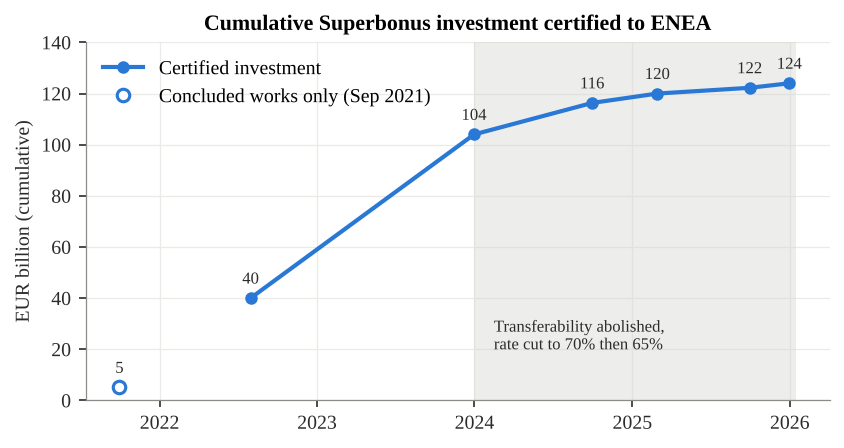

In [2]:
fig, ax = plt.subplots(figsize=(6.4, 3.1))
main = takeup[takeup.measure != "concluded works"]
early = takeup[takeup.measure == "concluded works"]
ax.plot(main.date, main.investment_eur_bn, color=BLUE, lw=2, marker="o", ms=5, label="Certified investment")
ax.plot(early.date, early.investment_eur_bn, ls="none", marker="o", ms=6, mfc="white", mec=BLUE, mew=1.5,
        label="Concluded works only (Sep 2021)")
for _, r in takeup.iterrows():
    ax.annotate(f"{r.investment_eur_bn:,.0f}", (r.date, r.investment_eur_bn), textcoords="offset points",
                xytext=(0, 7), ha="center", fontsize=8, color=INK)
ax.axvspan(pd.Timestamp("2024-01-01"), pd.Timestamp("2026-01-15"), color=LIGHT, alpha=0.45, lw=0)
ax.text(pd.Timestamp("2024-02-15"), 20, "Transferability abolished,\nrate cut to 70% then 65%", fontsize=8, color=INK)
ax.set_ylabel("EUR billion (cumulative)")
ax.set_ylim(0, 140)
ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_title("Cumulative Superbonus investment certified to ENEA")
ax.legend(loc="upper left")
save(fig, "fig1_takeup")

# growth between observations, EUR bn per month
m = main.set_index("date").investment_eur_bn
months = (m.index.to_series().diff().dt.days / 30.44)
rate = (m.diff() / months).round(2)
results["avg_monthly_2022_2023"] = float(rate.loc["2023-12-31"])
results["avg_monthly_2025"] = float(rate.loc["2025-12-31"])
rate

,building_type,certifications,investment_eur_bn,source,share_cert,share_inv,avg_k_eur
0,Condominiums,138352,83.0,ENEA report 30 Sep 2025 via Edilportale,27.6,67.9,599.9
1,Single-family homes,245184,27.9,ENEA report 30 Sep 2025 via Edilportale,48.9,22.8,113.8
2,Independent units,117386,11.3,ENEA report 30 Sep 2025 via Edilportale,23.4,9.2,96.3


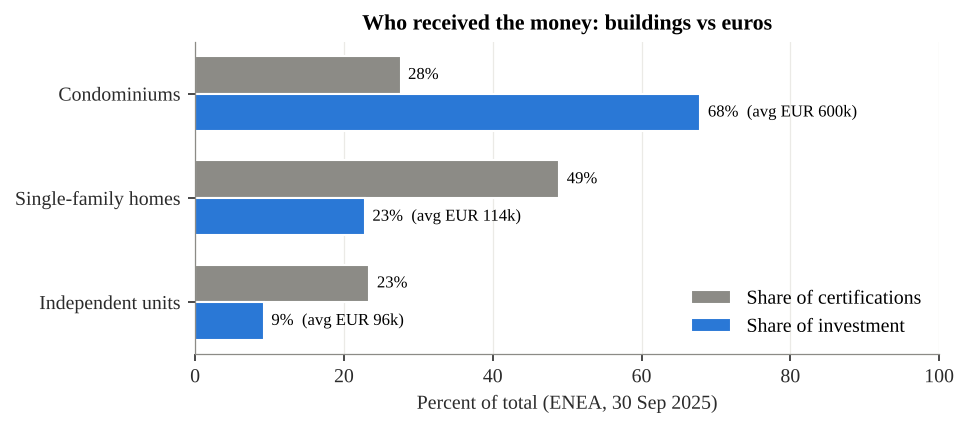

In [3]:
comp["share_cert"] = comp.certifications / comp.certifications.sum() * 100
comp["share_inv"] = comp.investment_eur_bn / comp.investment_eur_bn.sum() * 100
comp["avg_k_eur"] = comp.investment_eur_bn * 1e6 / comp.certifications   # thousand EUR per certification

fig, ax = plt.subplots(figsize=(6.4, 2.7))
y = np.arange(len(comp))[::-1]
h = 0.36
ax.barh(y + h/2, comp.share_cert, h, color=GREY, label="Share of certifications", edgecolor="white", lw=1)
ax.barh(y - h/2, comp.share_inv, h, color=BLUE, label="Share of investment", edgecolor="white", lw=1)
for yi, (_, r) in zip(y, comp.iterrows()):
    ax.text(r.share_cert + 1, yi + h/2, f"{r.share_cert:.0f}%", va="center", fontsize=8)
    ax.text(r.share_inv + 1, yi - h/2, f"{r.share_inv:.0f}%  (avg EUR {r.avg_k_eur:,.0f}k)", va="center", fontsize=8)
ax.set_yticks(y, comp.building_type)
ax.set_xlim(0, 100); ax.set_xlabel("Percent of total (ENEA, 30 Sep 2025)")
ax.set_title("Who received the money: buildings vs euros")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
save(fig, "fig2_composition")
results["condo_share_inv"] = round(float(comp.share_inv.iloc[0]), 1)
results["condo_share_cert"] = round(float(comp.share_cert.iloc[0]), 1)
comp.round(1)

## 3. Deficit footprint
- `building_credits_accrued_pct_gdp` = accrued cost of the credits in net borrowing (Corsello & Ercolani, 2025, approx. 1/3/4% of GDP for 2021–23).
- 2024 value is derived: the European Commission attributes about 3.5 points of the 2023→2024 deficit fall to lower credits, so 4.0 − 3.5 = 0.5.
- The "ex-credits" deficit is a pure accounting subtraction: it ignores second-round effects on GDP and revenue, so it is an **upper bound** on the improvement.

,year,net_borrowing_pct_gdp,credits,other,first_estimate_pct_gdp
0,2019,1.5,0.0,1.5,NaN
1,2020,9.4,0.0,9.4,9.5
2,2021,8.9,1.0,7.9,7.2
3,2022,8.1,3.0,5.1,5.6
4,2023,7.2,4.0,3.2,NaN
5,2024,3.4,0.5,2.9,NaN
6,2025,3.1,0.0,3.1,NaN


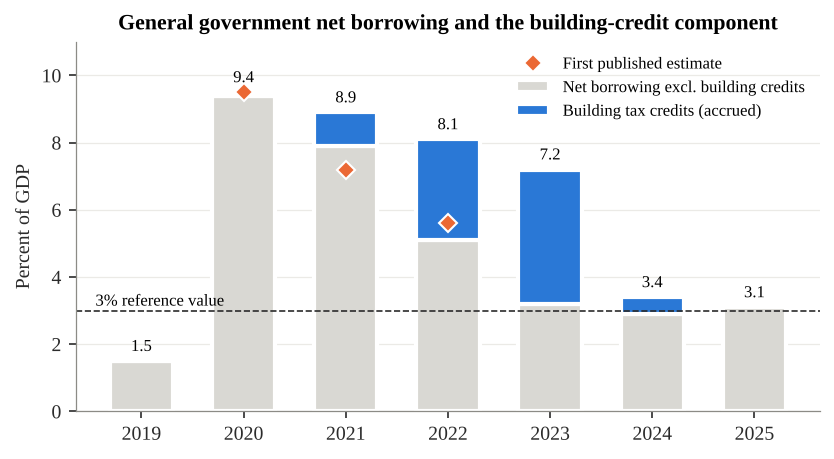

In [4]:
d = deficit.copy()
d["credits"] = d.building_credits_accrued_pct_gdp.fillna(0)
d["other"] = d.net_borrowing_pct_gdp - d.credits

fig, ax = plt.subplots(figsize=(6.4, 3.2))
x = d.year.values
ax.bar(x, d.other, 0.62, color=LIGHT, edgecolor="white", lw=2, label="Net borrowing excl. building credits")
ax.bar(x, d.credits, 0.62, bottom=d.other, color=BLUE, edgecolor="white", lw=2, label="Building tax credits (accrued)")
fe = d.dropna(subset=["first_estimate_pct_gdp"])
ax.plot(fe.year, fe.first_estimate_pct_gdp, ls="none", marker="D", ms=6, color=ORANGE, mec="white", mew=1,
        label="First published estimate")
for _, r in d.iterrows():
    top = max(r.net_borrowing_pct_gdp, r.first_estimate_pct_gdp if pd.notna(r.first_estimate_pct_gdp) else 0)
    ax.text(r.year, top + 0.3, f"{r.net_borrowing_pct_gdp:.1f}", ha="center", fontsize=8)
ax.axhline(3, color=INK, lw=0.8, ls="--")
ax.text(2018.55, 3.15, "3% reference value", fontsize=8)
ax.set_ylabel("Percent of GDP"); ax.set_ylim(0, 11)
ax.set_xticks(x)
ax.set_title("General government net borrowing and the building-credit component")
ax.legend(loc="upper right", fontsize=8)
ax.grid(axis="x", visible=False)
save(fig, "fig3_deficit")
results["deficit_ex_credits_2023"] = round(float(d.loc[d.year == 2023, "other"].iloc[0]), 1)
d[["year", "net_borrowing_pct_gdp", "credits", "other", "first_estimate_pct_gdp"]]

## 4. From deficit to debt: a cash-offset simulation
Payable tax credits hit the **deficit** when the work is done, but hit the **cash borrowing requirement (and so debt)** only when the holder offsets them against taxes.

Model (stylised):
- accrual in year $t$: $A_t$ (% of GDP), from Section 3;
- each vintage is used in $n_t$ equal instalments starting in $t+1$;
- cash cost in year $s$: $C_s = \sum_t \frac{A_t}{n_t}\,\mathbf{1}\{t < s \le t+n_t\}$.

Baseline instalments: 5 for 2021 works, 4 for 2022–23, 10 for 2024 (the 2024 rule reported by the IMF). Ratios are kept at a constant GDP, so the model shows **timing**, not a precise forecast.

2021    0.00
2022    0.20
2023    0.95
2024    1.95
2025    2.00
2026    2.00
2027    1.05
2028    0.05
2029    0.05
2030    0.05
2031    0.05
2032    0.05
2033    0.05
2034    0.05
dtype: float64

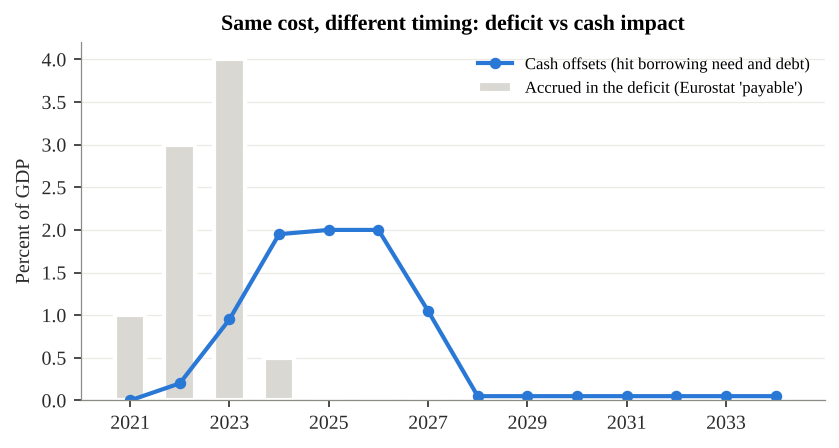

In [5]:
def cash_profile(accruals, instalments, start_lag=1, horizon=(2021, 2034)):
    # Spread each vintage of payable tax credits into equal annual offsets.
    # accruals: {year: % of GDP accrued}; instalments: {year: number of annual instalments}
    years = np.arange(horizon[0], horizon[1] + 1)
    cash = pd.Series(0.0, index=years)
    for t, a in accruals.items():
        n = instalments[t]
        for k in range(n):
            s = t + start_lag + k
            if s in cash.index:
                cash[s] += a / n
    return cash

acc = dict(zip(d.year, d.credits))
acc = {t: v for t, v in acc.items() if v > 0}            # 2021-2024
base_n = {2021: 5, 2022: 4, 2023: 4, 2024: 10}
cash = cash_profile(acc, base_n)
accr = pd.Series(acc).reindex(cash.index, fill_value=0)

fig, ax = plt.subplots(figsize=(6.4, 3.1))
ax.bar(cash.index, accr, 0.62, color=LIGHT, edgecolor="white", lw=2, label="Accrued in the deficit (Eurostat 'payable')")
ax.plot(cash.index, cash, color=BLUE, lw=2, marker="o", ms=4.5, label="Cash offsets (hit borrowing need and debt)")
ax.set_ylabel("Percent of GDP"); ax.set_xticks(cash.index[::2])
ax.set_title("Same cost, different timing: deficit vs cash impact")
ax.legend(loc="upper right", fontsize=8)
ax.grid(axis="x", visible=False)
save(fig, "fig4_cash_sim")

results["cash_2024_2026_avg"] = round(float(cash.loc[2024:2026].mean()), 2)
results["cash_2025_2027_sum"] = round(float(cash.loc[2025:2027].sum()), 2)
results["cash_after_2027_sum"] = round(float(cash.loc[2028:].sum()), 2)
results["total_accrued"] = round(float(accr.sum()), 2)
cash.round(2)

### Sensitivity (Table 2)
How much do the conclusions depend on the instalment assumptions?

In [6]:
scenarios = {
    "Baseline (5/4/4/10)": base_n,
    "All vintages in 4 instalments": {t: 4 for t in acc},
    "All vintages in 5 instalments": {t: 5 for t in acc},
    "2024 vintage in 4 (no 10-year rule)": {**base_n, 2024: 4},
}
rows = []
for name, n in scenarios.items():
    c = cash_profile(acc, n)
    rows.append({"Scenario": name,
                 "Peak year": int(c.idxmax()),
                 "Peak (% GDP)": round(c.max(), 2),
                 "2025-27 total (% GDP)": round(c.loc[2025:2027].sum(), 2),
                 "After 2027 (% GDP)": round(c.loc[2028:].sum(), 2)})
table2 = pd.DataFrame(rows)
table2.to_latex(FIG / "table2_sensitivity.tex", index=False, float_format="%.2f")
table2

,Scenario,Peak year,Peak (% GDP),2025-27 total (% GDP),After 2027 (% GDP)
0,Baseline (5/4/4/10),2025,2.00,5.05,0.35
1,All vintages in 4 instalments,2025,2.12,5.12,0.12
2,All vintages in 5 instalments,2025,1.70,4.90,1.00
3,2024 vintage in 4 (no 10-year rule),2025,2.08,5.28,0.12


## 5. How large must the multiplier be?
Let $s$ be the subsidy rate (cost per euro of subsidised work), $d$ the deadweight share, and $k$ the GDP effect of one euro of genuinely **additional** construction spending. The implied multiplier on public money is

$$m = \frac{k\,(1-d)}{s}.$$

Two thresholds:
- **output break-even**: $m = 1$;
- **self-financing** ("it pays for itself"): extra tax revenue $\tau\, m \ge 1$, i.e. $m \ge 1/\tau$ with $\tau = 42.7\%$ (Istat tax burden, 2022).

,study,take_up_eur_bn,deadweight_eur_bn,source,d,k_breakeven,k_selffin
0,Bank of Italy (Accetturo et al.),170,45,Fiscal Studies 47(1) 2026 / QEF 860,0.265,1.360,3.185
1,MEF Treasury working paper,186,70,MEF Department of the Treasury WP,0.376,1.603,3.755


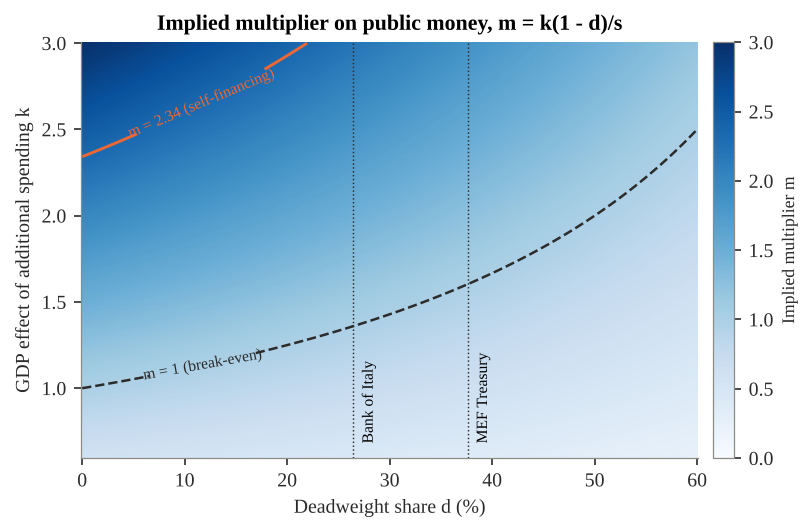

In [7]:
lit["d"] = lit.deadweight_eur_bn / lit.take_up_eur_bn
tau, s = 0.427, 1.0          # s = 1: blended rate of Superbonus (110%) and facades bonus (90%/60%)
lit["k_breakeven"] = s / (1 - lit.d)
lit["k_selffin"] = s / (tau * (1 - lit.d))

dd = np.linspace(0, 0.6, 241)
kk = np.linspace(0.6, 3.0, 241)
D, K = np.meshgrid(dd, kk)
M = K * (1 - D) / s

fig, ax = plt.subplots(figsize=(6.4, 3.6))
im = ax.pcolormesh(D * 100, K, M, cmap="Blues", shading="auto", vmin=0, vmax=3, rasterized=True)
cs = ax.contour(D * 100, K, M, levels=[1, 1 / tau], colors=[INK, ORANGE], linewidths=[1.2, 1.4],
                linestyles=["--", "-"])
ax.clabel(cs, fmt={1: "m = 1 (break-even)", 1 / tau: "m = 2.34 (self-financing)"}, fontsize=7.5)
for _, r in lit.iterrows():
    ax.axvline(r.d * 100, color=INK, lw=0.7, ls=":")
    ax.text(r.d * 100 + 0.8, 0.68, r.study.split(" (")[0].replace(" working paper", ""), rotation=90, fontsize=7.5,
            va="bottom")
cb = fig.colorbar(im, ax=ax, pad=0.02); cb.set_label("Implied multiplier m", fontsize=8.5)
ax.set_xlabel("Deadweight share d (%)"); ax.set_ylabel("GDP effect of additional spending k")
ax.set_title("Implied multiplier on public money, m = k(1 - d)/s")
ax.grid(False)
save(fig, "fig5_multiplier")

for _, r in lit.iterrows():
    key = "bdi" if "Bank" in r.study else "mef"
    results[f"d_{key}"] = round(r.d * 100, 1)
    results[f"k_breakeven_{key}"] = round(r.k_breakeven, 2)
    results[f"k_selffin_{key}"] = round(r.k_selffin, 2)
results["m_selffin"] = round(1 / tau, 2)
lit.round(3)

## 6. Construction costs
Corsello & Ercolani (2024, 2025): Istat's construction cost index rose about 13% between Sep 2021 and Dec 2023; the Superbonus explains about 5 points by end-2022 and about 7 points by end-2023.
The end-2022 total is not reported in the column, so only the end-2023 split is drawn.

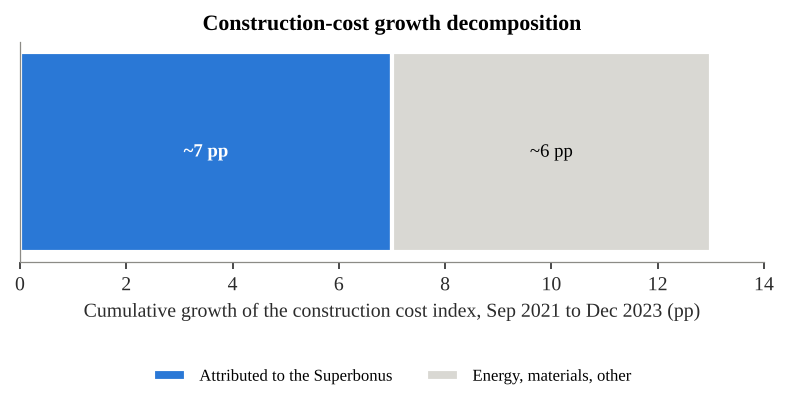

In [8]:
total, sb = 13.0, 7.0
fig, ax = plt.subplots(figsize=(6.4, 1.9))
ax.barh([0], [sb], color=BLUE, edgecolor="white", lw=2, label="Attributed to the Superbonus")
ax.barh([0], [total - sb], left=[sb], color=LIGHT, edgecolor="white", lw=2, label="Energy, materials, other")
ax.text(sb / 2, 0, f"~{sb:.0f} pp", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
ax.text(sb + (total - sb) / 2, 0, f"~{total - sb:.0f} pp", ha="center", va="center", fontsize=9)
ax.set_yticks([]); ax.set_xlim(0, 14); ax.set_xlabel("Cumulative growth of the construction cost index, Sep 2021 to Dec 2023 (pp)")
ax.set_title("Construction-cost growth decomposition")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.42), ncol=2, fontsize=8)
ax.grid(False)
save(fig, "fig6_costs")
results["cost_share_sb"] = round(sb / total * 100)

## 7. Export the numbers quoted in the paper

In [9]:
(FIG / "results.json").write_text(json.dumps(results, indent=2))
results

{'avg_monthly_2022_2023': 3.76,
 'avg_monthly_2025': 0.58,
 'condo_share_inv': 67.9,
 'condo_share_cert': 27.6,
 'deficit_ex_credits_2023': 3.2,
 'cash_2024_2026_avg': 1.98,
 'cash_2025_2027_sum': 5.05,
 'cash_after_2027_sum': 0.35,
 'total_accrued': 8.5,
 'd_bdi': 26.5,
 'k_breakeven_bdi': 1.36,
 'k_selffin_bdi': 3.19,
 'd_mef': 37.6,
 'k_breakeven_mef': 1.6,
 'k_selffin_mef': 3.76,
 'm_selffin': 2.34,
 'cost_share_sb': 54}